In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [9]:
from torchviz import make_dot

def render_graph(loss, params, filename="graph", format="png"):
    """
    Renders the autograd graph using torchviz.

    Args:
        loss (torch.Tensor): Final scalar tensor (e.g., loss)
        params (dict): Named parameters to show in graph
        filename (str): Output file name (without extension)
        format (str): File format (png, pdf, etc.)
    """
    dot = make_dot(loss, params=params)
    dot.format = format
    dot.render(filename, cleanup=True)
    return dot

In [12]:
# defaine cross_entropy raw

In [13]:
def softmax(x): return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
def nl(input, target): return -input[range(target.shape[0]), target].log().mean()

In [19]:
torch.manual_seed(3409)

xs = torch.randn(2,10, requires_grad=True)
ys = torch.tensor([9,4])
pred = softmax(xs)
loss=nl(pred, ys)
#loss = F.cross_entropy(xs, ys)
loss.backward()

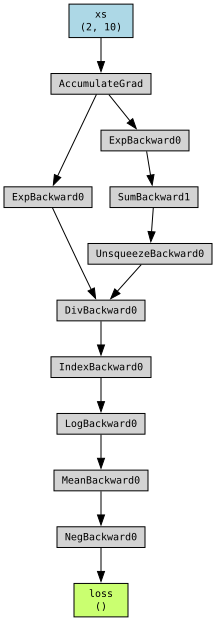

In [20]:
params = {
    "xs": xs,
    "pred": pred,
    "loss": loss
}

render_graph(loss, params, filename="logistic_graph")

In [22]:
def explore(fn, depth=0, max_depth=5):
    if fn is None or depth > max_depth:
        return
    print("  " * depth, fn)
    if hasattr(fn, 'next_functions'):
        for next_fn, _ in fn.next_functions:
            explore(next_fn, depth + 1, max_depth)

explore(loss.grad_fn, max_depth=10)

In [16]:
# with loss = F.cross_entropy(xs, ys)

In [23]:
torch.manual_seed(3409)

xs = torch.randn(2,10, requires_grad=True)
ys = torch.tensor([9,4])
#pred = softmax(xs)
#loss=nl(pred, ys)
loss = F.cross_entropy(xs, ys)
loss.backward()

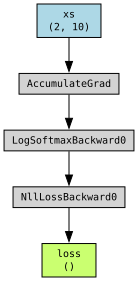

In [24]:
params = {
    "xs": xs,
    "loss": loss
}

render_graph(loss, params, filename="logistic_graph")

In [25]:
def explore(fn, depth=0, max_depth=5):
    if fn is None or depth > max_depth:
        return
    print("  " * depth, fn)
    if hasattr(fn, 'next_functions'):
        for next_fn, _ in fn.next_functions:
            explore(next_fn, depth + 1, max_depth)

explore(loss.grad_fn, max_depth=10)

In [26]:
xs[0]

tensor([ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
        -0.0902,  0.2235], grad_fn=<SelectBackward0>)

In [27]:
xs.data

tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]])

In [28]:
xs.grad

tensor([[ 0.0270,  0.1762,  0.0171,  0.0341,  0.0137,  0.0623,  0.1142,  0.0097,
          0.0193, -0.4736],
        [ 0.0321,  0.0239,  0.0082,  0.0081, -0.4637,  0.0414,  0.1195,  0.1219,
          0.0736,  0.0350]])